# 04 · Metrics, Segments & Charts

**Goal:** turn the SQL results into the final metrics, customer segments and charts used in the README.

1. KPI overview
2. Revenue trend
3. Top categories
4. Freight burden by state
5. Cohort retention heatmap
6. RFM segmentation
7. Delivery delay vs. review score

All charts are saved to `reports/figures/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

sys.path.append(str(Path("..").resolve()))
from src.db import get_engine, run_sql_file

pd.set_option("display.float_format", "{:,.2f}".format)
engine = get_engine()

FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

### Chart style

One consistent style for every chart: a validated colorblind-safe palette, thin marks, a recessive grid,
one y-axis per chart and text in neutral ink (never in the series colour).

In [2]:
SURFACE = "#fcfcfb"
TEXT = "#0b0b0b"
TEXT_2 = "#52514e"
GRID = "#e4e3df"
BLUE = "#2a78d6"     # main series
ORANGE = "#eb6834"   # highlight
GRAY = "#b9b8b3"     # context / de-emphasised
BLUE_RAMP = ["#f0efec", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.size": 10,
    "text.color": TEXT,
    "axes.labelcolor": TEXT_2,
    "axes.edgecolor": GRID,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 26,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": TEXT_2,
    "ytick.color": TEXT_2,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
    "legend.frameon": False,
})


def subtitle(ax, text):
    ax.text(0, 1.02, text, transform=ax.transAxes, color=TEXT_2, fontsize=10, va="bottom")


def save(fig, name):
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight")
    plt.show()


brl = mticker.FuncFormatter(lambda x, _: f"{x / 1e6:.1f}M" if x >= 1e6 else f"{x / 1e3:.0f}K")

## 1. KPI overview

In [3]:
kpi = pd.read_sql(
    """
    WITH order_revenue AS (
        SELECT o.order_id, o.is_late, SUM(oi.price + oi.freight_value) AS revenue
        FROM orders o JOIN order_items oi ON oi.order_id = o.order_id
        GROUP BY o.order_id, o.is_late
    )
    SELECT
        (SELECT COUNT(*) FROM orders)                                  AS orders,
        (SELECT COUNT(DISTINCT customer_unique_id) FROM customers)     AS customers,
        ROUND(SUM(revenue), 0)                                         AS revenue_brl,
        ROUND(AVG(revenue), 2)                                         AS aov_brl,
        ROUND(100.0 * AVG(is_late::int), 1)                            AS late_pct,
        (SELECT ROUND(AVG(review_score), 2) FROM order_reviews)        AS avg_review
    FROM order_revenue
    """,
    engine,
)
kpi.T.rename(columns={0: "value"})

,value
orders,"96,470.00"
customers,"93,350.00"
revenue_brl,"15,418,395.00"
aov_brl,159.83
late_pct,6.80
avg_review,4.16


## 2. Revenue trend

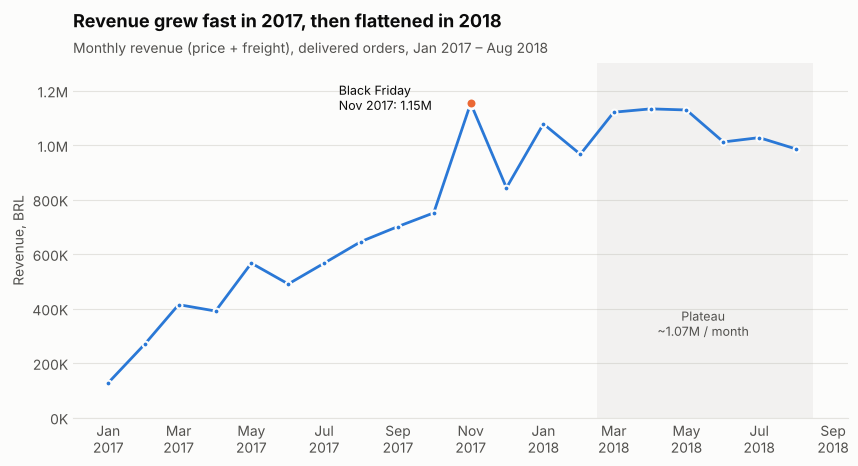

In [4]:
monthly = run_sql_file(engine, "01_monthly_revenue.sql")
monthly["month"] = pd.to_datetime(monthly["month"])

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(monthly["month"], monthly["revenue"], color=BLUE, linewidth=2)
ax.scatter(monthly["month"], monthly["revenue"], color=BLUE, s=18, zorder=3, edgecolor=SURFACE, linewidth=1.5)

peak = monthly.loc[monthly["revenue"].idxmax()]
ax.scatter([peak["month"]], [peak["revenue"]], color=ORANGE, s=60, zorder=4, edgecolor=SURFACE, linewidth=2)
ax.annotate("Black Friday\nNov 2017: 1.15M", (peak["month"], peak["revenue"]),
            xytext=(-95, 4), textcoords="offset points", color=TEXT, fontsize=9, va="center")

plateau = monthly[monthly["month"] >= "2018-03-01"]
ax.axvspan(pd.Timestamp("2018-02-15"), pd.Timestamp("2018-08-15"), color=GRAY, alpha=0.15, linewidth=0)
ax.text(pd.Timestamp("2018-05-15"), 300_000, f"Plateau\n~{plateau['revenue'].mean() / 1e6:.2f}M / month",
        ha="center", color=TEXT_2, fontsize=9)

ax.yaxis.set_major_formatter(brl)
ax.set_ylim(0, 1_300_000)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b\n%Y"))
ax.grid(axis="x", visible=False)
ax.set_ylabel("Revenue, BRL")
ax.set_title("Revenue grew fast in 2017, then flattened in 2018")
subtitle(ax, "Monthly revenue (price + freight), delivered orders, Jan 2017 – Aug 2018")
save(fig, "01_revenue_trend.png")

Monthly revenue rose ~8× during 2017 and has been flat at ~1.07M BRL since March 2018.
AOV stayed between 146 and 170 BRL the whole time, so growth came from order volume, not basket size.

## 3. Top categories

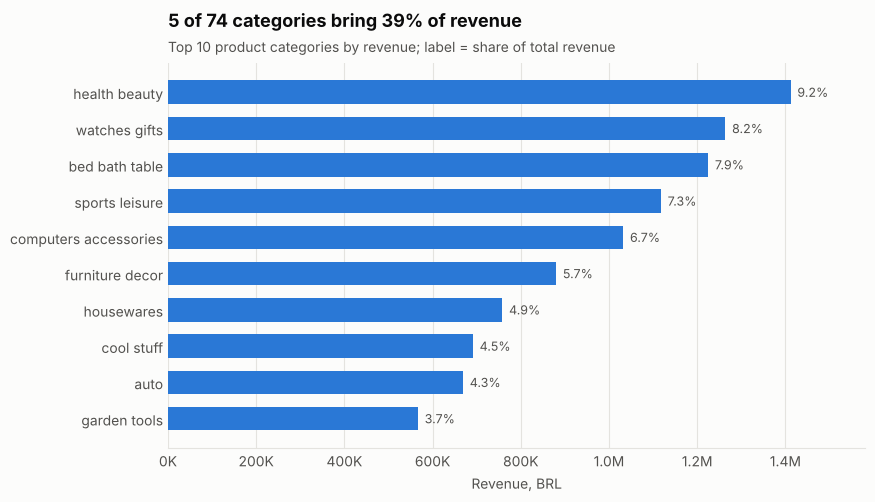

In [5]:
categories = run_sql_file(engine, "03_top_categories.sql").head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(categories["category"].str.replace("_", " "), categories["revenue"], color=BLUE, height=0.65)
for bar, share in zip(bars, categories["revenue_share_pct"]):
    ax.text(bar.get_width() + 15_000, bar.get_y() + bar.get_height() / 2,
            f"{share:.1f}%", va="center", color=TEXT_2, fontsize=9)

ax.xaxis.set_major_formatter(brl)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Revenue, BRL")
ax.set_xlim(0, categories["revenue"].max() * 1.12)
ax.set_title("5 of 74 categories bring 39% of revenue")
subtitle(ax, "Top 10 product categories by revenue; label = share of total revenue")
save(fig, "02_top_categories.png")

## 4. Freight burden by state

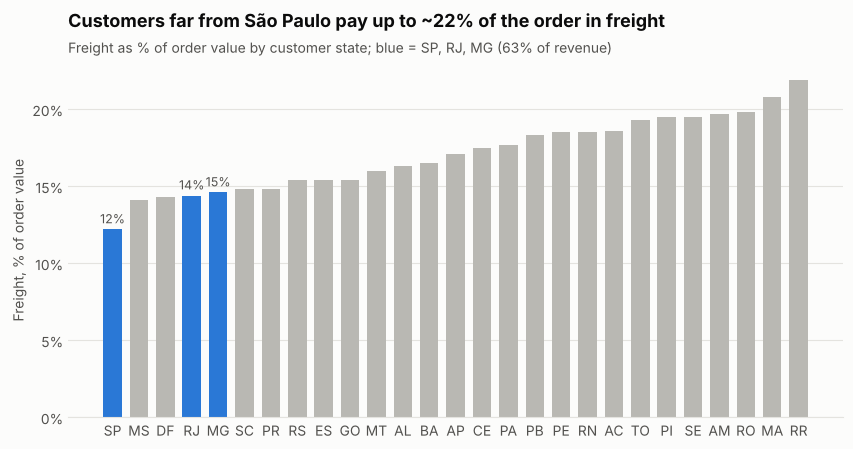

In [6]:
states = run_sql_file(engine, "04_revenue_by_state.sql").sort_values("freight_share_pct")
highlight = states["state"].isin(["SP", "RJ", "MG"])

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(states["state"], states["freight_share_pct"], color=np.where(highlight, BLUE, GRAY), width=0.7)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
ax.set_ylabel("Freight, % of order value")
for _, row in states[highlight].iterrows():
    ax.text(row["state"], row["freight_share_pct"] + 0.4, f"{row['freight_share_pct']:.0f}%",
            ha="center", color=TEXT_2, fontsize=9)
ax.set_title("Customers far from São Paulo pay up to ~22% of the order in freight")
subtitle(ax, "Freight as % of order value by customer state; blue = SP, RJ, MG (63% of revenue)")
save(fig, "03_freight_by_state.png")

## 5. Cohort retention heatmap

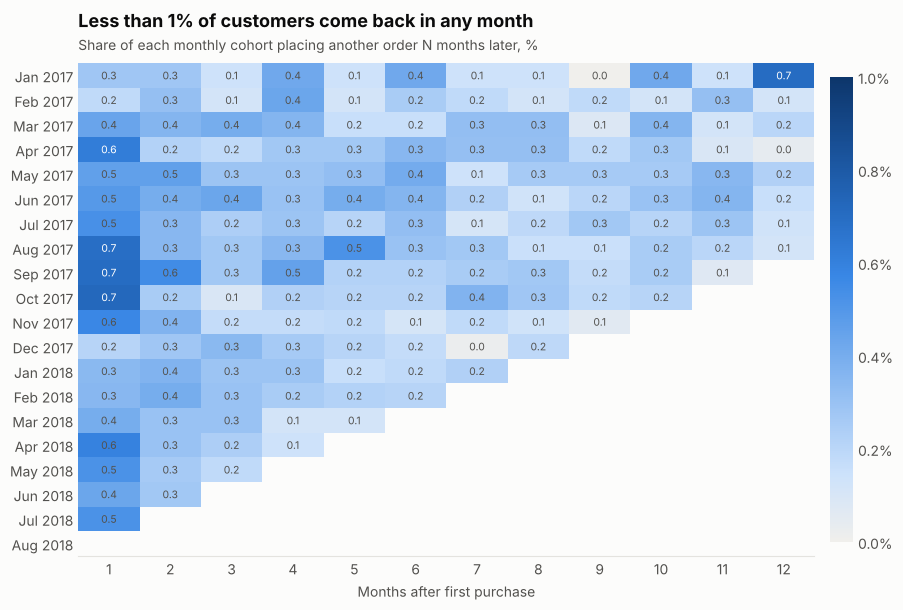

In [7]:
cohorts = run_sql_file(engine, "06_cohorts.sql")
retention = cohorts.pivot(index="cohort_month", columns="month_number", values="retention_pct")
retention.index = pd.to_datetime(retention.index)

last = retention.index.max()
for cohort in retention.index:
    observable = (last.year - cohort.year) * 12 + (last.month - cohort.month)
    cols = retention.columns <= observable
    retention.loc[cohort, cols] = retention.loc[cohort, cols].fillna(0)

heat = retention.loc[:, 1:12]   # month 0 is always 100%
cmap = LinearSegmentedColormap.from_list("blue_ramp", BLUE_RAMP)
cmap.set_bad(SURFACE)

fig, ax = plt.subplots(figsize=(10, 6.4))
im = ax.imshow(heat.values, cmap=cmap, vmin=0, vmax=1.0, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index.strftime("%b %Y"))
ax.grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7.5,
                    color="white" if v >= 0.6 else TEXT_2)
cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, format=mticker.PercentFormatter(decimals=1))
cbar.outline.set_visible(False)
cbar.ax.tick_params(colors=TEXT_2)
ax.set_xlabel("Months after first purchase")
ax.set_title("Less than 1% of customers come back in any month")
subtitle(ax, "Share of each monthly cohort placing another order N months later, %")
save(fig, "04_cohort_retention.png")

In [8]:
m1 = heat[1].dropna()
print(f"Month-1 retention: average {m1.mean():.2f}%, best {m1.max():.2f}% ({m1.idxmax():%b %Y})")
print(f"12-month cumulative repeat rate, 2017 cohorts: "
      f"{heat.loc['2017-01':'2017-08', 1:12].sum(axis=1).mean():.1f}% (upper bound, customers can repeat in several months)")

Month-1 retention: average 0.48%, best 0.72% (Oct 2017)
12-month cumulative repeat rate, 2017 cohorts: 3.3% (upper bound, customers can repeat in several months)


## 6. RFM segmentation

Scores come from `sql/07_rfm_base.sql`: R and M are quintiles (5 = best), F is 1 / 2 / 3+ orders
because 97% of customers bought only once.

| Segment | Rule | Meaning |
| --- | --- | --- |
| Champions | F ≥ 2, R ≥ 3 | repeat buyers, bought recently |
| Loyal, slipping | F ≥ 2, R ≤ 2 | repeat buyers who have not returned for a while |
| New high-value | F = 1, R ≥ 4, M ≥ 4 | first order recently, big basket |
| New low-value | F = 1, R ≥ 4, M ≤ 3 | first order recently, small basket |
| At risk, high-value | F = 1, R ≤ 3, M ≥ 4 | one big order long ago |
| Hibernating | F = 1, R ≤ 3, M ≤ 3 | one small order long ago |

In [9]:
rfm = run_sql_file(engine, "07_rfm_base.sql")


def segment(row):
    if row.f_score >= 2:
        return "Champions" if row.r_score >= 3 else "Loyal, slipping"
    if row.r_score >= 4:
        return "New high-value" if row.m_score >= 4 else "New low-value"
    return "At risk, high-value" if row.m_score >= 4 else "Hibernating"


rfm["segment"] = rfm.apply(segment, axis=1)
ORDER = ["Champions", "Loyal, slipping", "New high-value", "New low-value", "At risk, high-value", "Hibernating"]

segments = (
    rfm.groupby("segment")
    .agg(customers=("customer_unique_id", "count"),
         revenue=("monetary", "sum"),
         avg_spend=("monetary", "mean"),
         avg_recency_days=("recency_days", "mean"))
    .reindex(ORDER)
)
segments["customers_pct"] = 100 * segments["customers"] / segments["customers"].sum()
segments["revenue_pct"] = 100 * segments["revenue"] / segments["revenue"].sum()
segments

,customers,revenue,avg_spend,avg_recency_days,customers_pct,revenue_pct
segment,,,,,,
Champions,1807,"570,081.98",315.49,132.06,1.94,3.70
"Loyal, slipping",994,"294,105.48",295.88,382.14,1.06,1.91
New high-value,14400,"4,349,939.14",302.08,91.84,15.43,28.21
New low-value,21739,"1,584,252.56",72.88,90.40,23.29,10.28
"At risk, high-value",20701,"6,177,074.40",298.39,336.16,22.18,40.06
Hibernating,33709,"2,442,941.27",72.47,338.12,36.11,15.84


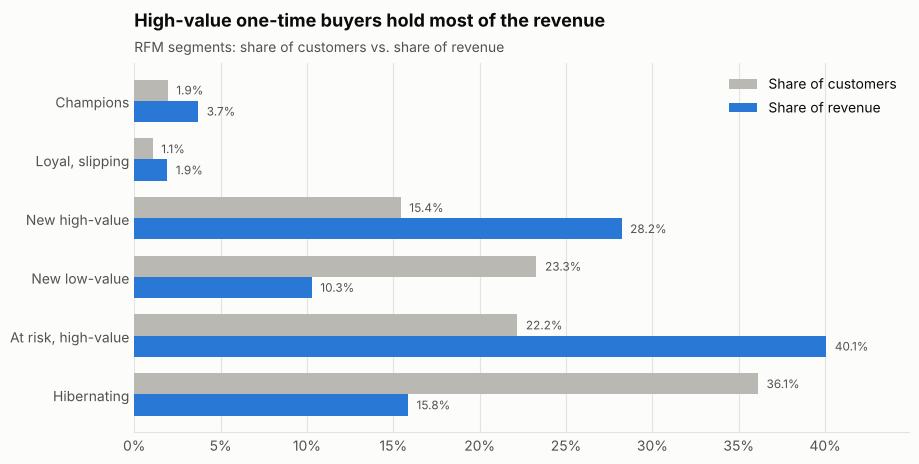

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(ORDER))[::-1]
h = 0.36
ax.barh(y + h / 2, segments["customers_pct"], height=h, color=GRAY, label="Share of customers")
ax.barh(y - h / 2, segments["revenue_pct"], height=h, color=BLUE, label="Share of revenue")
for yi, c, r in zip(y, segments["customers_pct"], segments["revenue_pct"]):
    ax.text(c + 0.5, yi + h / 2, f"{c:.1f}%", va="center", fontsize=8.5, color=TEXT_2)
    ax.text(r + 0.5, yi - h / 2, f"{r:.1f}%", va="center", fontsize=8.5, color=TEXT_2)
ax.set_yticks(y, ORDER)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(segments["customers_pct"].max(), segments["revenue_pct"].max()) * 1.12)
ax.legend(loc="upper right")
ax.set_title("High-value one-time buyers hold most of the revenue")
subtitle(ax, "RFM segments: share of customers vs. share of revenue")
save(fig, "05_rfm_segments.png")

**Insights**
- Repeat buyers (Champions + Loyal) are only ~3% of customers but spend ~2× more per person.
- **"At risk, high-value"** customers made one large order and never came back: they hold the biggest share of
  revenue and are the best target for a win-back campaign.
- **"New high-value"** customers bought recently: the right moment for a second-purchase offer, before they slip
  into the "at risk" group.

## 7. Delivery delay vs. review score

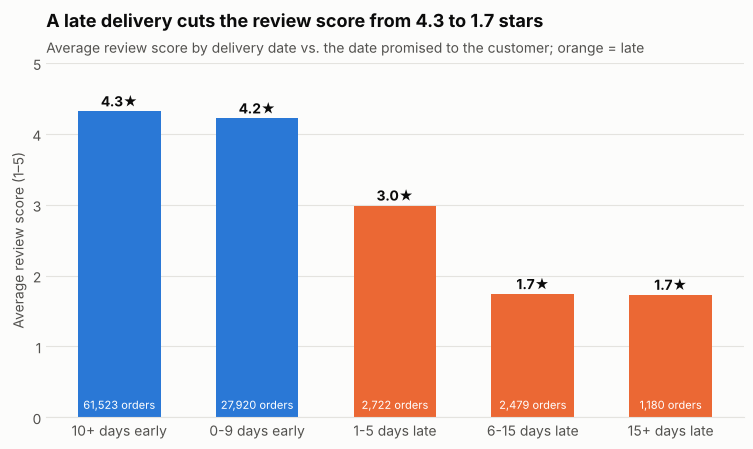

In [11]:
delivery = run_sql_file(engine, "08_delivery_vs_review.sql")
labels = delivery["delivery_vs_promise"].str[3:]
late = delivery["delivery_vs_promise"].str.contains("late")

fig, ax = plt.subplots(figsize=(9, 4.6))
bars = ax.bar(labels, delivery["avg_score"], color=np.where(late, ORANGE, BLUE), width=0.6)
for bar, score, n in zip(bars, delivery["avg_score"], delivery["orders"]):
    ax.text(bar.get_x() + bar.get_width() / 2, score + 0.07, f"{score:.1f}★",
            ha="center", color=TEXT, fontsize=10, fontweight="bold")
    ax.text(bar.get_x() + bar.get_width() / 2, 0.12, f"{n:,} orders",
            ha="center", color="white", fontsize=8)
ax.set_ylim(0, 5)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Average review score (1–5)")
ax.set_title("A late delivery cuts the review score from 4.3 to 1.7 stars")
subtitle(ax, "Average review score by delivery date vs. the date promised to the customer; orange = late")
save(fig, "06_delivery_vs_review.png")

## Summary

| Metric | Value |
| --- | --- |
| Delivered orders | 96,470 |
| Unique customers | 93,350 |
| Revenue | ~15.4M BRL |
| AOV | ~160 BRL |
| Repeat customers | 3.0% |
| Month-1 retention | < 1% for every cohort |
| Late deliveries | 6.8% |
| Avg score: on time / 5+ days late | 4.3 / 1.7 |

The charts in `reports/figures/` are used in the README together with the business recommendations.